### Run 16Bit model

In [3]:
from src.qwen_jax import load_params_and_config, QwenForCausalLM
import jax
import jax.numpy as jnp
import numpy as np

%load_ext autoreload
%autoreload 2

params, config = load_params_and_config("datasets/model_exports/qwen2.5_0.5B_float16")
jax_model = QwenForCausalLM(**config)
params

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


FrozenDict({
    params: {
        embed_tokens: {
            embedding: Array([[-1.007e-02,  4.199e-02,  9.888e-03, ...,  9.949e-03,  1.514e-02,
                    -7.050e-03],
                   [-1.465e-02,  6.032e-05, -1.843e-02, ..., -1.694e-03,  3.113e-03,
                    -8.423e-03],
                   [-3.662e-02, -9.827e-03,  6.989e-03, ..., -7.751e-03, -1.709e-02,
                    -1.049e-04],
                   ...,
                   [ 2.777e-03, -9.399e-03,  4.242e-03, ..., -6.561e-03, -1.062e-02,
                     1.721e-02],
                   [ 2.777e-03, -9.399e-03,  4.242e-03, ..., -6.561e-03, -1.062e-02,
                     1.721e-02],
                   [ 2.777e-03, -9.399e-03,  4.242e-03, ..., -6.561e-03, -1.062e-02,
                     1.721e-02]], dtype=float16),
        },
        layers_0: {
            input_layernorm: {
                weight: Array([-0.04614,  0.0437 , -0.02441,  0.0825 , -0.04102,  0.0376 ,
                       -0.0398 , -0.

In [4]:
with np.load("datasets/text_classification/boolq/train_data.npz") as data:
    input_ids = jnp.array(data['input_ids'])
    attention_mask = jnp.array(data['attention_mask'])
    labels = jnp.array(data['labels'])
    target_id = jnp.array(data['target_id'])
    all_target_ids = jnp.array(data['target_ids'])

input_ids.shape, attention_mask.shape, labels.shape, target_id.shape, all_target_ids.shape

((9400, 525), (9400, 525), (9400,), (9400,), (2, 1))

In [5]:
# Test forward pass with loaded Qwen model and dataset batch
# Assumes: jax_model, params, input_ids, attention_mask are already defined

# Forward pass (no gradient, inference mode)
outputs = jax_model.apply(params, input_ids[:4], attention_mask[:4], train=False)
print("Forward pass output shape:", outputs.shape)
print("Sample", outputs[0][-1])

Forward pass output shape: (4, 525, 151936)
Sample [ 4.184  4.152  2.436 ... -5.51  -5.516 -5.51 ]


### run with torch

In [13]:
params['params']['embed_tokens']['embedding'].dtype == jnp.float16

True

In [14]:
# Run equivalent forward pass using PyTorch (Transforms Qwen model)
import gc
gc.collect()
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForCausalLM

%load_ext autoreload
%autoreload 2

# Model name used in the torch notebook
MODEL_NAME = "Qwen/Qwen2.5-0.5B"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Target Device:", device)

# Load tokenizer and model (trust_remote_code matches torch notebook)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model_cfg = {
    'device_map': 'auto',
    'torch_dtype': torch.float16 if params['params']['embed_tokens']['embedding'].dtype == jnp.float16 else torch.float32,
    'trust_remote_code': False,
}
print("Loading PyTorch model (this may print a lot)...")
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **model_cfg)
model.eval()

# Prepare inputs (use data loaded earlier in the notebook)
# input_ids, attention_mask, labels, target_id were loaded from the dataset .npz
torch_input_ids = torch.from_numpy(np.array(input_ids[:4])).to(device)
torch_attention_mask = torch.from_numpy(np.array(attention_mask[:4])).to(device)

# Forward pass (no grad)
with torch.no_grad():
    torch_out = model(input_ids=torch_input_ids, attention_mask=torch_attention_mask)
    # torch_out = model(input_ids=torch_input_ids, attention_mask=torch.ones(4,300))

# Get logits (batch, seq_len, vocab)
torch_logits = torch_out.logits if hasattr(torch_out, 'logits') else torch_out[0]
print("Torch logits shape:", torch_logits.shape)

# Select last token logits (equivalent to outputs[:, -1] in JAX run)
torch_last = torch_logits[:, -1, :].cpu().numpy()
print("Selected last-token logits shape (torch):", torch_last.shape)

# If JAX outputs exist, compare numerically (outputs from JAX should be in variable `outputs`)
try:
    jax_last = np.array(outputs[:4, -1, :])
    abs_diff = np.abs(torch_last - jax_last)
    print("Comparison with JAX last-token logits:")
    print("  max abs diff:", float(abs_diff.max()))
    print("  mean abs diff:", float(abs_diff.mean()))
except NameError:
    print("JAX outputs not found in workspace; skipping numeric comparison.")

# Compute probabilities for the small set of target ids used earlier
all_ids = np.unique(np.array(target_id))
print("All unique target IDs:", all_ids)
torch_all_ids = torch.tensor(all_ids, dtype=torch.long).to(device)
torch_probs = torch.softmax(torch_logits[:, -1, :][:, torch_all_ids], dim=-1).cpu().numpy()
print("Probabilities shape (batch, n_targets):", torch_probs.shape)

# Map target_id entries to indices into all_ids (same mapping as JAX code) and pick the prob
torch_target_ids = np.array(target_id[:4]).reshape(-1, 1)
# mapping via argmax on equality
target_mask = (torch_target_ids == all_ids.reshape(1, -1)).argmax(axis=1).reshape(-1, 1)
selected_probs = np.take_along_axis(torch_probs, target_mask, axis=-1).squeeze(-1)
print("Selected target probabilities (per-sample):", selected_probs.tolist())

# Also show logits at the target positions
selected_logits = np.take_along_axis(torch_last, torch_target_ids, axis=-1).squeeze(-1)
print("Selected target logits (per-sample):", selected_logits.tolist())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Target Device: cuda


`torch_dtype` is deprecated! Use `dtype` instead!


Loading PyTorch model (this may print a lot)...
Torch logits shape: torch.Size([4, 525, 151936])
Selected last-token logits shape (torch): (4, 151936)
Comparison with JAX last-token logits:
  max abs diff: 0.20703125
  mean abs diff: 0.01491546630859375
All unique target IDs: [2514 4049]
Probabilities shape (batch, n_targets): (4, 2)
Selected target probabilities (per-sample): [0.79052734375, 0.83447265625, 0.85791015625, 0.81298828125]
Selected target logits (per-sample): [9.9609375, 11.796875, 10.8203125, 10.6015625]


#### compare

In [15]:
torch_last
jax_out = jnp.take_along_axis(outputs[:, -1], all_ids.reshape(1, -1), axis=-1)
torch_out = np.take_along_axis(torch_last, all_ids.reshape(1, -1), axis=-1)
print("JAX selected out:", jax_out)
print("Torch selected out:", torch_out)

JAX selected out: [[ 8.62   9.94 ]
 [10.12  11.74 ]
 [ 9.05  10.84 ]
 [ 9.125 10.586]]
Torch selected out: [[ 8.63  9.96]
 [10.18 11.8 ]
 [ 9.02 10.82]
 [ 9.13 10.6 ]]


### make comparision

#### 16Bit

In [1]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform"

from src.qwen_jax import load_params_and_config, QwenForCausalLM
import jax
import jax.numpy as jnp
import numpy as np

# Load JAX model
params, config = load_params_and_config("datasets/model_exports/qwen2.5_0.5B_float16")
jax_model = QwenForCausalLM(**config)


In [2]:
# Load Torch model
import gc
gc.collect()
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForCausalLM
from src.qwen_jax import QwenForCausalLM, load_params_and_config
import jax.numpy as jnp
import jax

%load_ext autoreload
%autoreload 2

# Model name used in the torch notebook
MODEL_NAME = "Qwen/Qwen2.5-0.5B"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Target Device:", device)

# Load tokenizer and model (trust_remote_code matches torch notebook)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model_cfg = {
    'device_map': 'auto',
    'torch_dtype': torch.float16 if params['params']['embed_tokens']['embedding'].dtype == jnp.float16 else torch.float32,
    'trust_remote_code': False,
}
print("Loading PyTorch model (this may print a lot)...")
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **model_cfg)
model.eval()

Target Device: cuda


`torch_dtype` is deprecated! Use `dtype` instead!


Loading PyTorch model (this may print a lot)...


Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 896)
    (layers): ModuleList(
      (0-23): 24 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=896, out_features=896, bias=True)
          (k_proj): Linear(in_features=896, out_features=128, bias=True)
          (v_proj): Linear(in_features=896, out_features=128, bias=True)
          (o_proj): Linear(in_features=896, out_features=896, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=896, out_features=4864, bias=False)
          (up_proj): Linear(in_features=896, out_features=4864, bias=False)
          (down_proj): Linear(in_features=4864, out_features=896, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((896,), eps=1e-06)
    (rotary_emb): Qwen2RotaryEmbe

In [3]:
# Load dataset batch
with np.load("datasets/text_classification/boolq/train_data.npz") as data:
    input_ids = jnp.array(data['input_ids'])
    attention_mask = jnp.array(data['attention_mask'])
    labels = jnp.array(data['labels'])
    target_id = jnp.array(data['target_id'])

input_ids.shape, attention_mask.shape, labels.shape, target_id.shape

((9400, 525), (9400, 525), (9400,), (9400,))

In [4]:
gc.collect()

73

In [5]:
out = []
torch_out = []
batch_size = 8
cpu = jax.devices("cpu")[0]
for i in range(input_ids.shape[0]//batch_size):
    print(f"Batch {i+1}")
    inbut_batch = input_ids[i*batch_size:(i+1)*batch_size]
    attn_batch = attention_mask[i*batch_size:(i+1)*batch_size]
    # Forward pass (no gradient, inference mode)
    outputs = jax_model.apply(params, inbut_batch, attn_batch, train=False)
    out.append(jax.device_put(outputs, cpu))

    gc.collect()
    with torch.no_grad():
        torch_outputs = model(input_ids=torch.from_numpy(np.array(inbut_batch)).to(device), attention_mask=torch.from_numpy(np.array(attn_batch)).to(device))
        torch_outputs = torch_outputs.logits.cpu().numpy()
        torch_out.append(torch_outputs)
    if i >= 5:
        break

    torch.cuda.empty_cache()
    gc.collect()
    
out = jnp.concatenate(out, axis=0)
torch_out = np.concatenate(torch_out, axis=0)
out.shape, torch_out.shape


Batch 1
Batch 2
Batch 3
Batch 4
Batch 5
Batch 6


((48, 525, 151936), (48, 525, 151936))

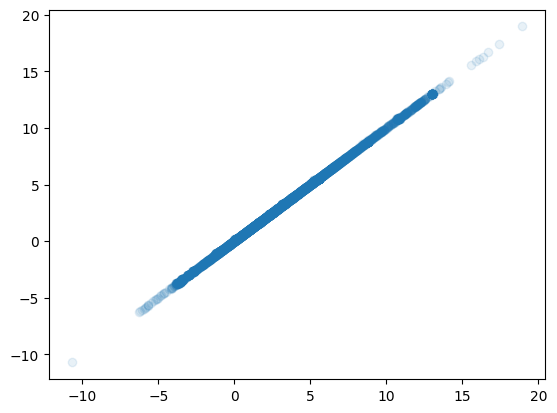

In [6]:
from matplotlib import pyplot as plt
plt.scatter(out[:, :, 36].flatten(), torch_out[:, :, 36].flatten(), alpha=0.1)

Max diff: 0.6016
Mean diff: 0.02809


Text(0.5, 1.0, 'Per-token difference between JAX and Torch outputs')

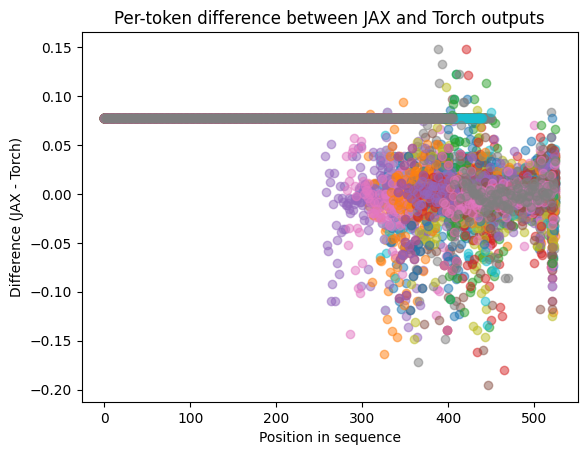

In [7]:
from matplotlib import pyplot as plt

diff = out - torch_out
print("Max diff:", jnp.abs(diff).max())
print("Mean diff:", jnp.abs(diff).mean())
y = diff[:,:,36].reshape(diff.shape[0], -1)
x = np.tile(np.arange(y.shape[-1]), (y.shape[0], 1))
for i in range(x.shape[0]):
    plt.scatter(x[i], y[i], alpha=0.5) 
plt.ylabel("Difference (JAX - Torch)")
plt.xlabel("Position in sequence")
plt.title("Per-token difference between JAX and Torch outputs")

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
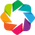

:RGB   [jax,torch]   (R,G,B,A)

In [6]:
import datashader as ds
import pandas as pd
import colorcet as co

import holoviews as hv
import panel as pn
import holoviews.operation.datashader as hd
import datashader.transfer_functions as tf

hv.extension('bokeh')

# Prepare data for datashader
df_plot = pd.DataFrame({
    'jax': out[:, :, 36].flatten().astype(np.float32),
    'torch': torch_out[:, :, 36].flatten().astype(np.float32)
})

# Create a canvas
canvas = ds.Canvas(plot_width=800, plot_height=800)
agg = canvas.points(df_plot, 'jax', 'torch')

# Render the image
# img = tf.shade(agg, cmap=co.fire, how='linear')

# hv.output(backend='bokeh')
# hd.shade(hv.Image(agg), cmap=co.fire, width=800, height=800)
# # Display the shaded image with a colorbar using holoviews
# pn.extension('bokeh')

# img_hv = hv.RGB(img)
# colorbar = pn.widgets.ColorBar(
#     color_mapper=img.data['cmap'],
#     orientation='vertical',
#     width=50,
#     height=800,
#     value=0
# )
# pn.Row(img_hv.opts(width=800, height=800), colorbar)
hd.shade(hv.Image(agg), cmap=co.fire, width=800, height=800, how='linear')


Text(0, 0.5, 'Torch output')

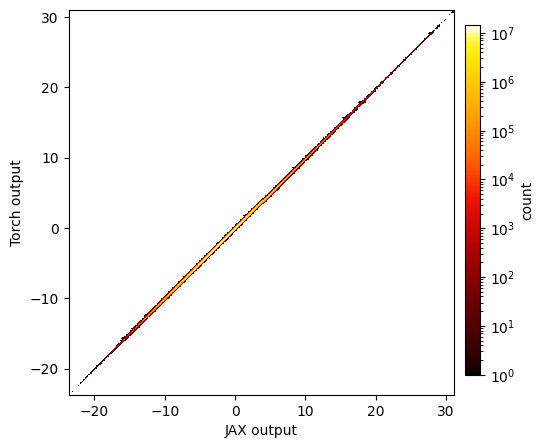

In [7]:
import datashader as ds
import pandas as pd
import colorcet as co
import holoviews as hv
import panel as pn
import holoviews.operation.datashader as hd
import datashader.transfer_functions as tf
from datashader.mpl_ext import dsshow
from matplotlib import pyplot as plt

fig = plt.figure(figsize=(5, 5))
ax = plt.gca()

df_plot = pd.DataFrame({
    'jax': out[:, :, :50000].flatten().astype(np.float32),
    'torch': torch_out[:, :, :50000].flatten().astype(np.float32)
})
artist0 = dsshow(df_plot, ds.Point('jax', 'torch'), ds.count(), aspect='equal', ax=ax, cmap=co.fire, norm='log')

plt.colorbar(artist0, cax=fig.add_axes([0.92, 0.15, 0.03, 0.7]));
# fig.gca().set_title('Point density (linear scale)')
fig.gca().set_ylabel('count')
ax.set_xlabel('JAX output')
ax.set_ylabel('Torch output')

/tmp/ipykernel_242827/3985373137.py:9: RuntimeWarning: divide by zero encountered in divide
  r_error = np.abs(diff) / np.abs(torch_out[:, :, :10000].flatten().astype(np.float32))


Text(0, 0.5, 'difference')

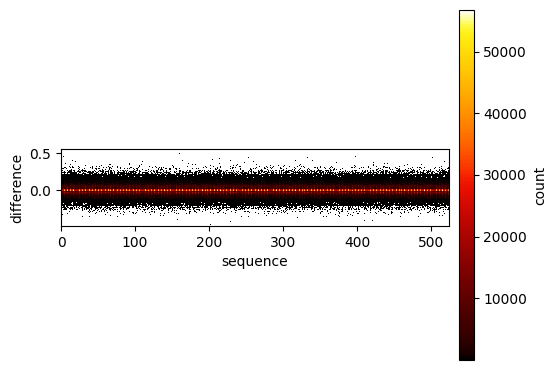

In [8]:
from datashader.mpl_ext import dsshow
from matplotlib import pyplot as plt

fig = plt.figure(figsize=(5, 5))
ax = plt.gca()

# Prepare data for datashader
diff = torch_out[:, :, :10000].flatten().astype(np.float32) - out[:, :, :10000].flatten().astype(np.float32)
r_error = np.abs(diff) / np.abs(torch_out[:, :, :10000].flatten().astype(np.float32))
r_error = diff
df_plot = pd.DataFrame({
    # 'sequence': np.tile(np.arange(0, out.shape[1], dtype=np.float32), (out.shape[0]*out.shape[2])),
    'sequence': np.tile(np.arange(0, out.shape[1], dtype=np.float32), (out.shape[0])*10000),
    'relative_error': r_error
})

artist0 = dsshow(df_plot, ds.Point('sequence', 'relative_error'), ds.count(), ax=ax, cmap=co.fire, norm='linear', plot_width=400, plot_height=400, aspect=100)

plt.colorbar(artist0, cax=fig.add_axes([0.92, 0.15, 0.03, 0.7]));
# fig.gca().set_title('Point density (linear scale)')
fig.gca().set_ylabel('count')
ax.set_xlabel('sequence')
ax.set_ylabel('difference')
# ax.set_ylim(-5, 5)

/tmp/ipykernel_2114694/3985373137.py:9: RuntimeWarning: divide by zero encountered in divide
  r_error = np.abs(diff) / np.abs(torch_out[:, :, :10000].flatten().astype(np.float32))


Text(0, 0.5, 'difference')

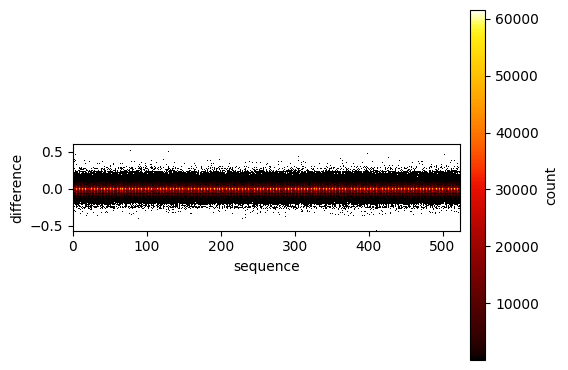

In [30]:
from datashader.mpl_ext import dsshow
from matplotlib import pyplot as plt

fig = plt.figure(figsize=(5, 5))
ax = plt.gca()

# Prepare data for datashader
diff = torch_out[:, :, :10000].flatten().astype(np.float32) - out[:, :, :10000].flatten().astype(np.float32)
r_error = np.abs(diff) / np.abs(torch_out[:, :, :10000].flatten().astype(np.float32))
r_error = diff
df_plot = pd.DataFrame({
    # 'sequence': np.tile(np.arange(0, out.shape[1], dtype=np.float32), (out.shape[0]*out.shape[2])),
    'sequence': np.tile(np.arange(0, out.shape[1], dtype=np.float32), (out.shape[0])*10000),
    'relative_error': r_error
})

artist0 = dsshow(df_plot, ds.Point('sequence', 'relative_error'), ds.count(), ax=ax, cmap=co.fire, norm='linear', plot_width=400, plot_height=400, aspect=100)

plt.colorbar(artist0, cax=fig.add_axes([0.92, 0.15, 0.03, 0.7]));
# fig.gca().set_title('Point density (linear scale)')
fig.gca().set_ylabel('count')
ax.set_xlabel('sequence')
ax.set_ylabel('difference')
# ax.set_ylim(-5, 5)

Text(0, 0.5, '(JAX - Torch) / mean(|Torch|)')

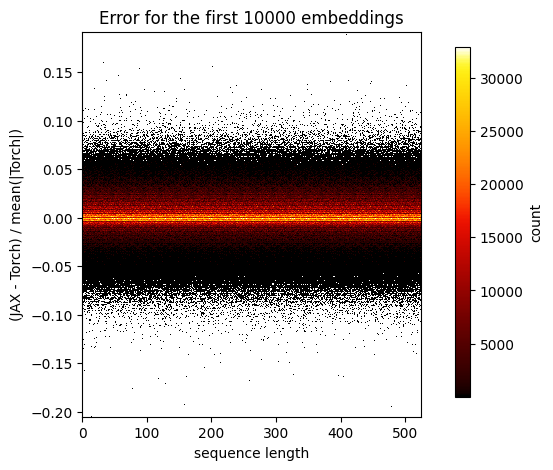

In [43]:
from datashader.mpl_ext import dsshow
from matplotlib import pyplot as plt

fig = plt.figure(figsize=(5, 5))
ax = plt.gca()
ax.set_title("Error for the first 10000 embeddings")

# Prepare data for datashader
diff = out[:, :, :10000].flatten().astype(np.float32) - torch_out[:, :, :10000].flatten().astype(np.float32)
r_error = diff / (np.abs(torch_out[:, :, :10000].flatten().astype(np.float32))).mean()
df_plot = pd.DataFrame({
    # 'sequence': np.tile(np.arange(0, out.shape[1], dtype=np.float32), (out.shape[0]*out.shape[2])),
    'sequence': np.tile(np.arange(0, out.shape[1], dtype=np.float32), (out.shape[0])*10000),
    'relative_error': r_error
})

artist0 = dsshow(df_plot, ds.Point('sequence', 'relative_error'), ds.count(), ax=ax, cmap=co.fire, norm='linear', plot_width=out.shape[1], plot_height=400, aspect=1500)

plt.colorbar(artist0, cax=fig.add_axes([0.92, 0.15, 0.03, 0.7]));
# fig.gca().set_title('Point density (linear scale)')
fig.gca().set_ylabel('count')
ax.set_xlabel('sequence length')
ax.set_ylabel('(JAX - Torch) / mean(|Torch|)')
# ax.set_ylim(-5, 5)

In [ ]:
diff = torch_out.flatten().astype(np.float32) - out.flatten().astype(np.float32)
print("Max diff:", np.abs(diff).max())
print("Mean diff:", np.abs(diff).mean())

Max diff: 0.6015625
Mean diff: 0.028091336


#### 32Bit

In [44]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform"

from src.qwen_jax import load_params_and_config, QwenForCausalLM
import jax
import jax.numpy as jnp
import numpy as np

# Load JAX model
params, config = load_params_and_config("datasets/model_exports/qwen2.5_0.5B_float32")
jax_model = QwenForCausalLM(**config)


In [45]:
# Load Torch model
import gc
gc.collect()
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForCausalLM
from src.qwen_jax import QwenForCausalLM, load_params_and_config
import jax.numpy as jnp
import jax

%load_ext autoreload
%autoreload 2

# Model name used in the torch notebook
MODEL_NAME = "Qwen/Qwen2.5-0.5B"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Target Device:", device)

# Load tokenizer and model (trust_remote_code matches torch notebook)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model_cfg = {
    'device_map': 'auto',
    'torch_dtype': torch.float16 if params['params']['embed_tokens']['embedding'].dtype == jnp.float16 else torch.float32,
    'trust_remote_code': False,
}
print("Loading PyTorch model (this may print a lot)...")
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **model_cfg)
model.eval()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Target Device: cuda
Loading PyTorch model (this may print a lot)...


Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 896)
    (layers): ModuleList(
      (0-23): 24 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=896, out_features=896, bias=True)
          (k_proj): Linear(in_features=896, out_features=128, bias=True)
          (v_proj): Linear(in_features=896, out_features=128, bias=True)
          (o_proj): Linear(in_features=896, out_features=896, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=896, out_features=4864, bias=False)
          (up_proj): Linear(in_features=896, out_features=4864, bias=False)
          (down_proj): Linear(in_features=4864, out_features=896, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((896,), eps=1e-06)
    (rotary_emb): Qwen2RotaryEmbe

In [46]:
# Load dataset batch
with np.load("datasets/text_classification/boolq/train_data.npz") as data:
    input_ids = jnp.array(data['input_ids'])
    attention_mask = jnp.array(data['attention_mask'])
    labels = jnp.array(data['labels'])
    target_id = jnp.array(data['target_id'])

input_ids.shape, attention_mask.shape, labels.shape, target_id.shape

((9400, 525), (9400, 525), (9400,), (9400,))

In [47]:
gc.collect()

44

In [48]:
out = []
torch_out = []
batch_size = 8
cpu = jax.devices("cpu")[0]
for i in range(input_ids.shape[0]//batch_size):
    print(f"Batch {i+1}")
    inbut_batch = input_ids[i*batch_size:(i+1)*batch_size]
    attn_batch = attention_mask[i*batch_size:(i+1)*batch_size]
    # Forward pass (no gradient, inference mode)
    outputs = jax_model.apply(params, inbut_batch, attn_batch, train=False)
    out.append(jax.device_put(outputs, cpu))

    gc.collect()
    with torch.no_grad():
        torch_outputs = model(input_ids=torch.from_numpy(np.array(inbut_batch)).to(device), attention_mask=torch.from_numpy(np.array(attn_batch)).to(device))
        torch_outputs = torch_outputs.logits.cpu().numpy()
        torch_out.append(torch_outputs)
    if i >= 5:
        break

    torch.cuda.empty_cache()
    gc.collect()
    
out = jnp.concatenate(out, axis=0)
torch_out = np.concatenate(torch_out, axis=0)
out.shape, torch_out.shape


Batch 1
Batch 2
Batch 3
Batch 4
Batch 5
Batch 6


((48, 525, 151936), (48, 525, 151936))

In [13]:
import datashader as ds
import pandas as pd
import colorcet as co
import holoviews as hv
import panel as pn
import holoviews.operation.datashader as hd
import datashader.transfer_functions as tf
from datashader.mpl_ext import dsshow
from matplotlib import pyplot as plt

Text(0, 0.5, 'Torch output')

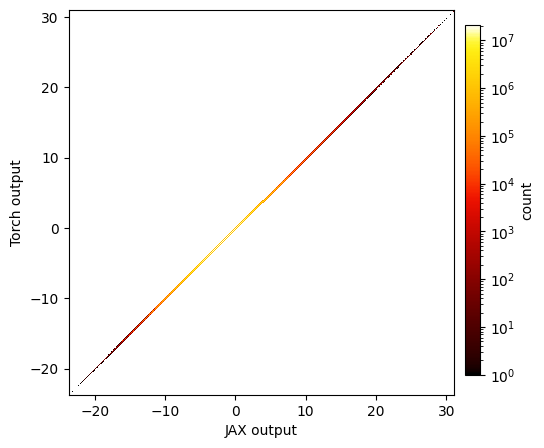

In [ ]:
import datashader as ds
import pandas as pd
import colorcet as co
import holoviews as hv
import panel as pn
import holoviews.operation.datashader as hd
import datashader.transfer_functions as tf
from datashader.mpl_ext import dsshow
from matplotlib import pyplot as plt

fig = plt.figure(figsize=(5, 5))
ax = plt.gca()

df_plot = pd.DataFrame({
    'jax': out[:, :, :50000].flatten().astype(np.float32),
    'torch': torch_out[:, :, :50000].flatten().astype(np.float32)
})
artist0 = dsshow(df_plot, ds.Point('jax', 'torch'), ds.count(), aspect='equal', ax=ax, cmap=co.fire, norm='log')

plt.colorbar(artist0, cax=fig.add_axes([0.92, 0.15, 0.03, 0.7]));
# fig.gca().set_title('Point density (linear scale)')
fig.gca().set_ylabel('count')
ax.set_xlabel('JAX output')
ax.set_ylabel('Torch output')

In [21]:
out.shape

(48, 525, 151936)

Text(0, 0.5, '(JAX - Torch) / mean(|Torch|)')

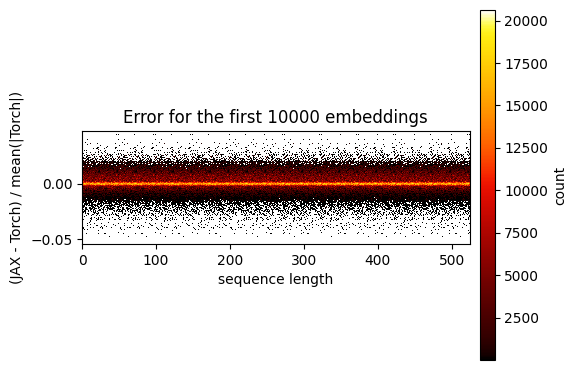

In [49]:
from datashader.mpl_ext import dsshow
from matplotlib import pyplot as plt

fig = plt.figure(figsize=(5, 5))
ax = plt.gca()
ax.set_title("Error for the first 10000 embeddings")

# Prepare data for datashader
diff = out[:, :, :10000].flatten().astype(np.float32) - torch_out[:, :, :10000].flatten().astype(np.float32)
r_error = diff / (np.abs(torch_out[:, :, :10000].flatten().astype(np.float32))).mean()
df_plot = pd.DataFrame({
    # 'sequence': np.tile(np.arange(0, out.shape[1], dtype=np.float32), (out.shape[0]*out.shape[2])),
    'sequence': np.tile(np.arange(0, out.shape[1], dtype=np.float32), (out.shape[0])*10000),
    'relative_error': r_error
})

artist0 = dsshow(df_plot, ds.Point('sequence', 'relative_error'), ds.count(), ax=ax, cmap=co.fire, norm='linear', plot_width=out.shape[1], plot_height=400, aspect=1500)

plt.colorbar(artist0, cax=fig.add_axes([0.92, 0.15, 0.03, 0.7]));
# fig.gca().set_title('Point density (linear scale)')
fig.gca().set_ylabel('count')
ax.set_xlabel('sequence length')
ax.set_ylabel('(JAX - Torch) / mean(|Torch|)')
# ax.set_ylim(-5, 5)

In [10]:
# 32bit
diff = torch_out.flatten().astype(np.float32) - out.flatten().astype(np.float32)
print("Max diff:", np.abs(diff).max())
print("Mean diff:", np.abs(diff).mean())

Max diff: 0.16838896
Mean diff: 0.0140297795
